# Kinematic slip on a triangular mesh

This tutorial builds the kinematic and static Green's functions of a fault meshed with triangles, with `TriangularPatchesKin`, and uses them to make a synthetic data set: the Pedernales-like synthetic of the pull request that introduced the class. The fault is a curved, slab-like surface whose dip steepens with depth; the stations are on land, as for a subduction earthquake; the data are bandpassed displacement waveforms, static GPS offsets and an InSAR line of sight.

The waveforms come from `pyrockoengine`, a waveform engine on [pyrocko](https://pyrocko.org) Green's function stores, which tabulate the seismograms of point sources in a layered earth model. This notebook uses the store `crust2_2hz_d0` (about 5 GB):

```bash
fomosto download kinherd crust2_2hz_d0
```

The static Green's functions come from the same engine, so that the waveforms and the static data share their earth model; with [cuokada](https://github.com/earthdef/cuOkada) installed, they are also compared with those of a homogeneous half space.

The files written at the end are those the kinematic model on triangular meshes of [AlTar 2](https://github.com/lijun99/altar) reads.

In [1]:
import os
import time
import warnings
# csi's docstrings hold escape sequences python warns about, unrelated to this tutorial
warnings.filterwarnings('ignore', category=SyntaxWarning)
import numpy as np
import matplotlib.pyplot as plt
import csi

# the directory of the pyrocko stores
store_dir = os.environ.get('PYROCKO_STORES', os.path.expanduser('~/gfstores'))

## The fault

The slab strikes N30°E; its top is at 5 km depth, and its dip steepens from 10° above 10 km to 27° at 50 km. `buildCurvedFault` integrates that dip down the slab and cuts the surface into 8 × 8 cells, each into two triangles, 128 patches. Every cross-section along strike is the same, so the surface unrolls flat: its surface coordinates, the distances along strike and down dip measured on the fault, are exact.

In [2]:
# the slab: strike N30E, its dip from 10 degrees above 10 km to 27 at 50 km, its top at 5 km
dip = lambda z: np.clip(10.0 + 17.0 * (z - 10.0) / 40.0, 10.0, 27.0)
fault = csi.TriangularPatchesKin("pedernales", lon0=-80.0, lat0=0.0, verbose=False)
fault.buildCurvedFault(lon=-80.6, lat=-0.8, depth=5.0, strike=30.0, dip=dip, length=160.0,
                       width=160.0, nstrike=8, ndip=8)
Np = len(fault.patch)
print(f"{Np} patches, depth {fault.Vertices[:, 2].min():.1f} to {fault.Vertices[:, 2].max():.1f} km")

# the surface coordinates against the lengths of the edges in space
V, F, uv = fault.Vertices, fault.Faces, fault.uv
edges = [(0, 1), (1, 2), (2, 0)]
space = np.array([np.linalg.norm(V[f[a]] - V[f[b]]) for f in F for a, b in edges])
surface = np.array([np.linalg.norm(uv[f[a]] - uv[f[b]]) for f in F for a, b in edges])
print(f"edges: {space.min():.1f} to {space.max():.1f} km; surface coordinates off by at most {1e3 * np.abs(space - surface).max():.1f} m")

128 patches, depth 5.0 to 47.8 km
edges: 20.0 to 28.3 km; surface coordinates off by at most 3.1 m


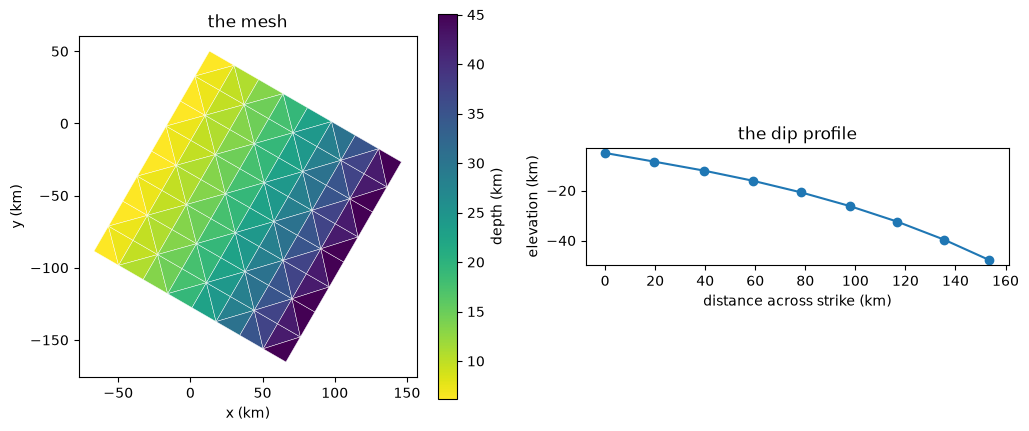

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
depth = V[F].mean(1)[:, 2]
pc = ax1.tripcolor(V[:, 0], V[:, 1], F, facecolors=depth, cmap='viridis_r', edgecolors='w', lw=0.3)
fig.colorbar(pc, ax=ax1, label='depth (km)')
ax1.set_aspect('equal'); ax1.set_xlabel('x (km)'); ax1.set_ylabel('y (km)'); ax1.set_title('the mesh')
# the down-dip profile: the vertices of the first column, against their horizontal distance from the top edge
column = np.isclose(uv[:, 0], 0.0)
x0, y0 = fault.ll2xy(-80.6, -0.8)
phi = np.radians(30.0)
horizontal = (V[column, 0] - x0) * np.cos(phi) - (V[column, 1] - y0) * np.sin(phi)
ax2.plot(horizontal, -V[column, 2], 'o-')
ax2.set_aspect('equal'); ax2.set_xlabel('distance across strike (km)'); ax2.set_ylabel('elevation (km)')
ax2.set_title('the dip profile')
plt.show()

## Rakes and source points

The slip of each patch has two components: along the convergence of the Nazca plate, N83°E, and across it. `convergenceRakes` gives the rake of each patch for slip along the convergence: the hanging wall moving against the subducting plate, projected on the patch. The rake across the convergence is 90° more.

A patch tens of kilometres across radiates differently from a point at its centroid. `setSourcePoints(3)` cuts each triangle into 3 × 3 smaller ones and places a point source at the centroid of each; the Green's functions of a patch sum the seismograms of its nine points, each with a ninth of its moment, and AlTar takes the rupture time at each of them, so that a patch slips progressively as the rupture front crosses it.

In [4]:
fault.setSourcePoints(3)
# slip along the convergence of the Nazca plate, N83E, and across it
parallel = fault.convergenceRakes(83.0)
rakes = (parallel + 90.0, parallel)
print(f"rake along the convergence: {parallel.min():.1f} to {parallel.max():.1f} degrees")
print(f"source points: {fault.sources_per_patch} a patch, {len(fault.sources_xyz)} in all")

rake along the convergence: 127.4 to 129.6 degrees
source points: 9 a patch, 1152 in all


## Stations

The stations are on land, east of a coast 45 km from the trench, and at least 1 km from every source point: a few high-rate GPS or strong motion stations for the waveforms, GPS stations for the static offsets, and the points of an InSAR-like grid. This tutorial uses fewer of them than the synthetic of the pull request, to compute faster. Each set is a `csi.seismic` object.

In [5]:
rng = np.random.default_rng(2016)
coast = 45.0
sources = fault.sources_xyz[:, :2]
# a point at {a} km along strike and {c} km east of the trench, across it
point = lambda a, c: (x0 + a * np.sin(phi) + c * np.cos(phi), y0 + a * np.cos(phi) - c * np.sin(phi))

def land(count, near, far, spread=20.0):
    # {count} places on land, {near} to {far} km east of the coast, at least 1 km from every source
    places = []
    while len(places) < count:
        a, c = rng.uniform(-spread, 160.0 + spread), coast + rng.uniform(near, far)
        x, y = point(a, c)
        if np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0:
            places.append((x, y))
    return np.array(places)

def stations(name, places, prefix):
    names = [f"{prefix}{k:03d}" for k in range(len(places))]
    data = csi.seismic(name, lon0=-80.0, lat0=0.0)
    data.setStat(names, *fault.xy2ll(places[:, 0], places[:, 1]), loc_format="LL")
    return data

kinematic = stations("kinematic", land(8, 2.0, 120.0), "K")
gps = stations("gps", land(15, 2.0, 150.0), "G")
ga, gc = np.meshgrid(np.linspace(-10, 170, 8), coast + np.linspace(3, 100, 6), indexing="ij")
insar_xy = np.array([point(a, c) for a, c in zip(ga.ravel(), gc.ravel())])
insar_xy = insar_xy[[np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0 for x, y in insar_xy]]
insar = stations("insar", insar_xy, "I")
print(f"{len(kinematic.sta_name)} waveform stations, {len(gps.sta_name)} gps, {len(insar.sta_name)} line of sight points")

8 waveform stations, 15 gps, 34 line of sight points


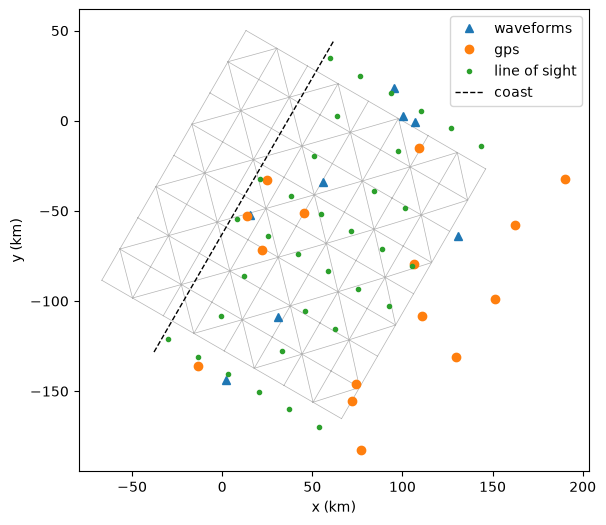

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.triplot(V[:, 0], V[:, 1], F, color='0.7', lw=0.5)
for data, marker, label in [(kinematic, '^', 'waveforms'), (gps, 'o', 'gps'), (insar, '.', 'line of sight')]:
    x, y = fault.ll2xy(np.asarray(data.lon), np.asarray(data.lat))
    ax.plot(x, y, marker, label=label)
ax.plot(*point(np.array([-20, 180]), coast), 'k--', lw=1, label='coast')
ax.set_aspect('equal'); ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)'); ax.legend()
plt.show()

## The kinematic Green's functions

`buildKinGFs` computes the seismograms of each patch for a unit slip along each rake, released by a triangle of 2 s centred at time 0, on a time axis that starts 40 s early: some stores have small precursors before the arrivals, which the engine reports if they fall before the axis. The seismograms are bandpassed between 0.015 and 0.08 Hz, as the data would be.

`buildBigGD` then makes the big G of AlTar's kinematic model: one column per time step of 1 s, rake and patch, the seismograms delayed by the time step, so that the data are big G times the slip history, the slip each patch releases in each time step.

In [7]:
engine = csi.pyrockoengine("crust2_2hz_d0", store_dir, delta=1.0)
fault.setMu(engine.material)
start = time.perf_counter()
fault.buildKinGFs(kinematic, engine, Dt=1.0, npts=160, rakes=rakes, points=True,
                  bandpass=(0.015, 0.08))
fault.buildBigGD(kinematic, Nt=85, Dt=1.0)
print(f"{time.perf_counter() - start:.0f} s; precursors cut off: {engine.lost:.1e} of a station's peak at most")
print(f"big G: {fault.bigG.shape[0]} data samples x {fault.bigG.shape[1]} slip windows (85 steps x 2 rakes x {Np} patches)")
print(f"shear modulus: {fault.mu.min() / 1e9:.0f} to {fault.mu.max() / 1e9:.0f} GPa")

7 s; precursors cut off: 4.8e-05 of a station's peak at most
big G: 3840 data samples x 21760 slip windows (85 steps x 2 rakes x 128 patches)
shear modulus: 36 to 72 GPa


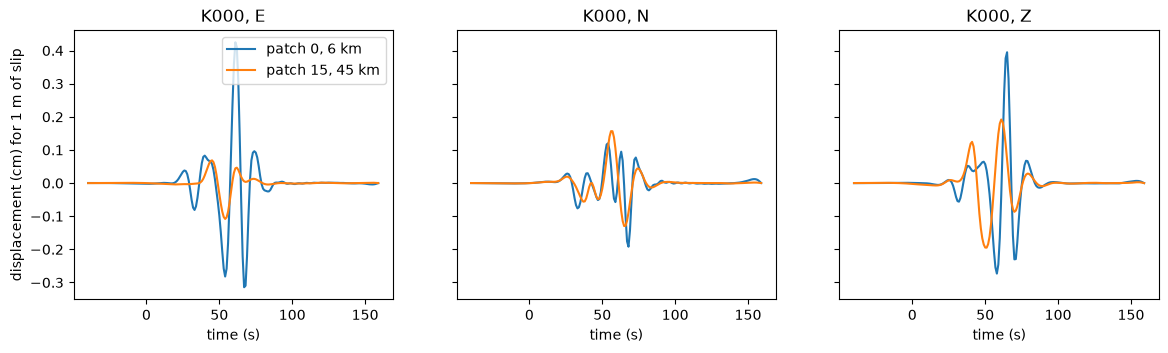

In [8]:
# the seismograms of a patch near the trench and of a deep one, at the first station, for slip along the convergence
G = fault.G[kinematic.name][1]
t = (np.arange(G.shape[-1]) - fault.kin_pre) * fault.kin_delta
shallow, deep = np.argmin(depth), np.argmax(depth)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for c, ax in enumerate(axes):
    for p, label in [(shallow, f'patch {shallow}, {depth[shallow]:.0f} km'), (deep, f'patch {deep}, {depth[deep]:.0f} km')]:
        ax.plot(t, 100 * G[p, 0, c], label=label)
    ax.set_title(f"{kinematic.sta_name[0]}, {'ENZ'[c]}"); ax.set_xlabel('time (s)')
axes[0].set_ylabel('displacement (cm) for 1 m of slip'); axes[0].legend()
plt.show()

## The static Green's functions

`buildStaticGFs` takes the final values of the seismograms of the same engine, unfiltered and long enough for the waves to pass, so that the static data share the earth model of the waveforms. The InSAR Green's functions are projected on the line of sight of a descending track.

With `method='cuokada'` (or `'cutde'`), they are those of triangular dislocations in a homogeneous half space instead. The two differ, a layered earth against a homogeneous one, but their patterns must agree: a comparison catches a mix-up of signs or rakes.

In [9]:
start = time.perf_counter()
Ggps = fault.buildStaticGFs(gps, engine, rakes=rakes, points=True)
Gins = fault.buildStaticGFs(insar, engine, rakes=rakes, points=True)
los = np.array([0.62, -0.11, 0.78])  # east, north, up: a descending track
Glos = np.einsum("c,scp->sp", los, Gins.reshape(len(insar.sta_name), 3, -1))
print(f"{time.perf_counter() - start:.0f} s; gps {Ggps.shape}, line of sight {Glos.shape}")

39 s; gps (45, 256), line of sight (34, 256)


engine against half space, column by column: correlation median 0.988, lowest 0.970; amplitude ratio median 1.08


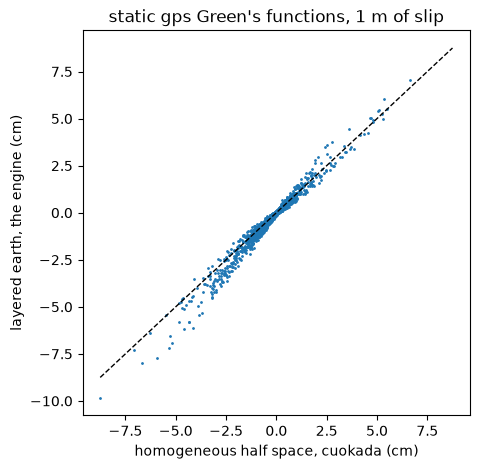

In [10]:
try:
    import cuokada
except ImportError:
    cuokada = None
    print("cuokada is not installed: no comparison with the half space")
if cuokada is not None:
    Ghs = fault.buildStaticGFs(gps, rakes=rakes, method='cuokada')
    corr = [np.corrcoef(Ggps[:, k], Ghs[:, k])[0, 1] for k in range(Ggps.shape[1])]
    ratio = np.linalg.norm(Ggps, axis=0) / np.linalg.norm(Ghs, axis=0)
    print(f"engine against half space, column by column: correlation median {np.median(corr):.3f}, lowest {np.min(corr):.3f}; "
          f"amplitude ratio median {np.median(ratio):.2f}")
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot(100 * Ghs.ravel(), 100 * Ggps.ravel(), '.', ms=2)
    lim = 100 * np.abs(Ghs).max()
    ax.plot([-lim, lim], [-lim, lim], 'k--', lw=1)
    ax.set_xlabel('homogeneous half space, cuokada (cm)'); ax.set_ylabel('layered earth, the engine (cm)')
    ax.set_title('static gps Green\'s functions, 1 m of slip')
    plt.show()

## A synthetic rupture

The true model of the Pedernales-like synthetic: a 3 m asperity next to the hypocentre in the north, a 6 m one 70 km south, slip across the convergence of up to 0.3 m, and rise times from 4 to 10 s that grow with the slip. Here the rupture front spreads at a constant 2.5 km/s from the hypocentre; on this slab, which unrolls flat, the distance along the fault between two points is the straight distance between their surface coordinates, so the onsets are exact. (AlTar solves the eikonal equation on the mesh instead, which also handles a rupture velocity that varies from patch to patch.)

The slip history follows AlTar's kinematic model: each source point of a patch releases its share of the slip as a triangle of the rise time, starting at its onset, and the slip of the patch in each time step is that function sampled at the start of the step. The data are then big G times the slip history for the waveforms, and the static Green's functions times the final slip for the GPS and the line of sight.

In [11]:
# the true model, on the centroids of the patches in surface coordinates
uvc = np.array([uv[f].mean(0) for f in F])
a = np.exp(-((uvc - [118.0, 60.0]) ** 2).sum(1) / (2 * 15.0 ** 2))
b = np.exp(-((uvc - [55.0, 75.0]) ** 2).sum(1) / (2 * 18.0 ** 2))
slip_parallel = 0.2 + 3.0 * a + 6.0 * b
slip_across = 0.3 * (a - b)
risetime = 4.0 + 6.0 * (slip_parallel - slip_parallel.min()) / (slip_parallel.max() - slip_parallel.min())
hypocenter, velocity = np.array([125.0, 55.0]), 2.5

# the onset at each source point, and the slip history Mb[Nt][2][Np], the components in the order of the rakes
Nt, dt = 85, 1.0
onset = np.linalg.norm(fault.sources_uv - hypocenter, axis=1) / velocity
half = (risetime / 2)[fault.sources_patch]
tk = np.arange(Nt) * dt
shape = np.clip(1 - np.abs(onset[:, None] + half[:, None] - tk[None, :]) / half[:, None], 0, None) / half[:, None]
rate = np.zeros((Np, Nt))
np.add.at(rate, fault.sources_patch, shape / fault.sources_per_patch)
Mb = np.stack([(rate * slip_across[:, None]).T, (rate * slip_parallel[:, None]).T], axis=1)
moment = (fault.mu * np.asarray(fault.area) * 1e6 * np.hypot(slip_across, slip_parallel)).sum()
print(f"Mw {2 / 3 * (np.log10(moment) - 9.1):.2f}; the rupture lasts {onset.max() + risetime.max():.0f} s of the {Nt} s of slip windows")

# the data
waveforms = fault.bigG @ Mb.ravel()
final = np.concatenate([slip_across, slip_parallel])
offsets, line_of_sight = Ggps @ final, Glos @ final
print(f"waveforms: {waveforms.size} samples, peak {100 * np.abs(waveforms).max():.1f} cm; "
      f"gps: peak {100 * np.abs(offsets).max():.1f} cm; line of sight: {100 * line_of_sight.min():.1f} to {100 * line_of_sight.max():.1f} cm")

Mw 7.90; the rupture lasts 74 s of the 85 s of slip windows
waveforms: 3840 samples, peak 31.6 cm; gps: peak 137.0 cm; line of sight: -86.8 to 7.7 cm


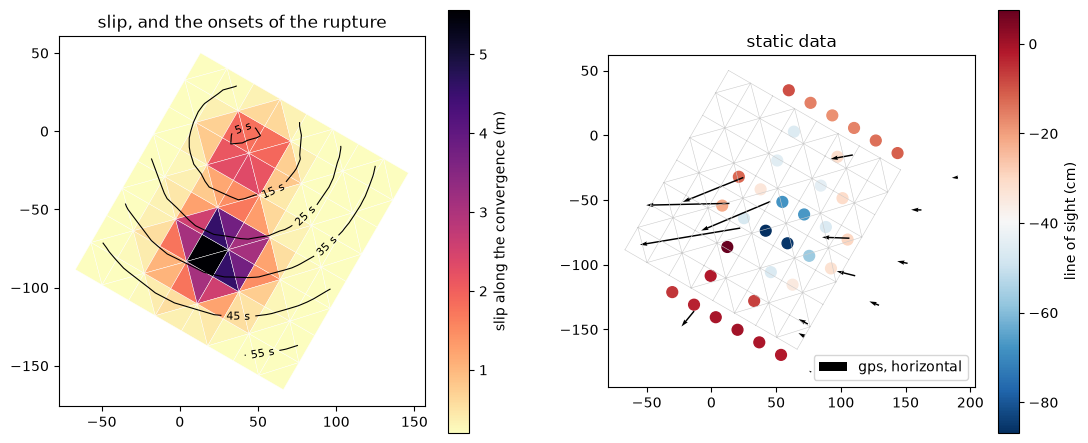

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
pc = ax1.tripcolor(V[:, 0], V[:, 1], F, facecolors=slip_parallel, cmap='magma_r', edgecolors='w', lw=0.3)
fig.colorbar(pc, ax=ax1, label='slip along the convergence (m)')
patch_onset = np.bincount(fault.sources_patch, weights=onset) / fault.sources_per_patch
centroids = V[F].mean(1)
cs = ax1.tricontour(centroids[:, 0], centroids[:, 1], patch_onset, levels=np.arange(5, 75, 10), colors='k', linewidths=0.8)
ax1.clabel(cs, fmt='%d s', fontsize=8)
ax1.set_aspect('equal'); ax1.set_title('slip, and the onsets of the rupture')
# the gps offsets and the line of sight
gx, gy = fault.ll2xy(np.asarray(gps.lon), np.asarray(gps.lat))
ix, iy = fault.ll2xy(np.asarray(insar.lon), np.asarray(insar.lat))
sc = ax2.scatter(ix, iy, c=100 * line_of_sight, cmap='RdBu_r', s=60)
fig.colorbar(sc, ax=ax2, label='line of sight (cm)')
o = offsets.reshape(-1, 3)
ax2.quiver(gx, gy, o[:, 0], o[:, 1], scale=5, width=0.004, label='gps, horizontal')
ax2.triplot(V[:, 0], V[:, 1], F, color='0.8', lw=0.4)
ax2.set_aspect('equal'); ax2.set_title('static data'); ax2.legend(loc='lower right')
plt.show()

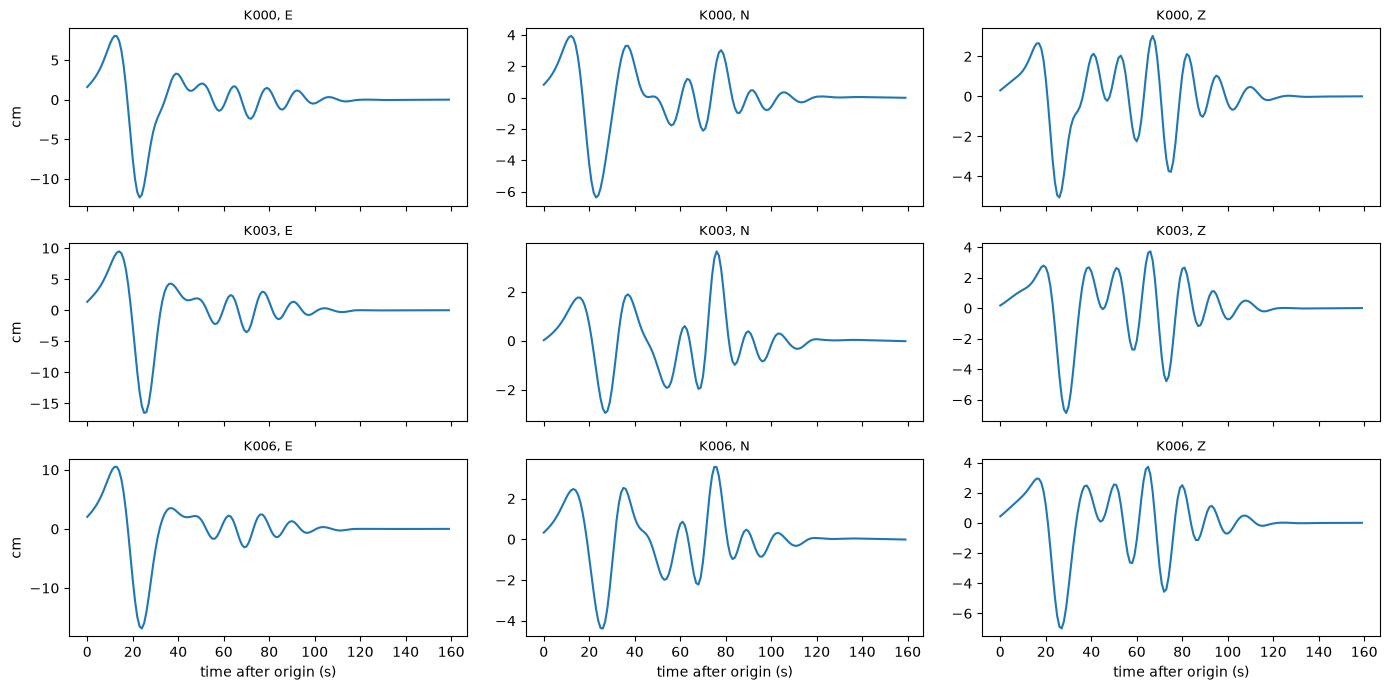

In [13]:
# the waveforms at three stations
traces = waveforms.reshape(len(kinematic.sta_name), 3, -1)
t = np.arange(traces.shape[-1]) * fault.kin_delta
fig, axes = plt.subplots(3, 3, figsize=(14, 7), sharex=True)
for row, s in enumerate([0, 3, 6]):
    for c in range(3):
        axes[row, c].plot(t, 100 * traces[s, c])
        axes[row, c].set_title(f"{kinematic.sta_name[s]}, {'ENZ'[c]}", fontsize=9)
    axes[row, 0].set_ylabel('cm')
for ax in axes[-1]:
    ax.set_xlabel('time after origin (s)')
fig.tight_layout()
plt.show()

## The files for AlTar

`saveKinematic` writes the mesh, its surface coordinates, the source points and the hypocentre (`mesh.h5`), the big G (`kinematicG.gf.h5`), and the waveforms, if `bigD` holds them (`kinematicG.data.h5`): the inputs of AlTar's kinematic model on triangular meshes, `altar.models.seismic.kinematicmesh`, which samples the slips, rise times, rupture velocities and hypocentre from them.

In [14]:
os.makedirs('kinematic_mesh', exist_ok=True)
os.chdir('kinematic_mesh')
fault.setHypoOnFault(*hypocenter)
fault.bigD = waveforms
fault.saveKinematic('mesh.h5')
import h5py
for name in ['mesh.h5', 'kinematicG.gf.h5', 'kinematicG.data.h5']:
    with h5py.File(name) as h5:
        print(name + ':', ', '.join(f"{k} {h5[k].shape}" for k in h5 if isinstance(h5[k], h5py.Dataset)))
os.chdir('..')

mesh.h5: area (128,), faces (128, 3), hypocenter (2,), uv (81, 2), vertices (81, 3)
kinematicG.gf.h5: kinematicG.gf (21760, 3840)
kinematicG.data.h5: kinematicG.data (3840,)
